# 第 4 章配套 Notebook：图矩阵表示、Kipf-Welling GCN 与消息传递三种聚合

[![Open In Colab (main)](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Casey-sketch-cyber/gnn2gsnn/blob/main/notion/notebooks/ch04_graphs_and_gnn.ipynb) （PR 审查期分支链接：[点此在 Colab 打开 gemini/deep-01 版](https://colab.research.google.com/github/Casey-sketch-cyber/gnn2gsnn/blob/gemini/deep-01/notion/notebooks/ch04_graphs_and_gnn.ipynb)）

> **运行环境**：仅需 Python ≥ 3.10、`numpy`、`matplotlib`，不需要 GPU，也不依赖 PyTorch 等深度学习框架。所有矩阵每一步的中间数值均直接打印并与第 4 章正文手算结果逐位核对一致。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib

# 配置中文与负号显示（Windows / Linux / macOS / Colab 通用回退）
matplotlib.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Noto Sans CJK SC', 'Arial Unicode MS', 'DejaVu Sans']
matplotlib.rcParams['axes.unicode_minus'] = False
np.set_printoptions(precision=6, suppress=True)
print("NumPy version:", np.__version__)


NumPy version: 2.5.5


## 1. 验收标准第 1 条手算复现：3 节点图、2 维特征、$2\times 2$ 权重矩阵的一层 GCN

对应第 4 章手算例 4.1：
- 3 个节点连成链 $1 - 2 - 3$；
- 特征矩阵 $X \in \mathbb{R}^{3\times 2} = \begin{bmatrix} 1 & 0 \\ 2 & 1 \\ 0 & 3 \end{bmatrix}$；
- 权重矩阵 $W \in \mathbb{R}^{2\times 2} = \begin{bmatrix} 1 & -1 \\ 2 & 1 \end{bmatrix}$；
- 逐步打印 $A, \tilde{A}, \tilde{D}, \hat{A}, \hat{A}X, \hat{A}XW, H^{(1)} = \mathrm{ReLU}(\hat{A}XW)$ 及每个矩阵的形状。

In [2]:
# 3 节点链状无向图：边 (1,2) 和 (2,3)
A3 = np.array([
    [0., 1., 0.],
    [1., 0., 1.],
    [0., 1., 0.],
])
X3 = np.array([
    [1., 0.],
    [2., 1.],
    [0., 3.],
])
W3 = np.array([
    [1., -1.],
    [2.,  1.],
])

I3 = np.eye(3)
A3_tilde = A3 + I3
d3_tilde = A3_tilde.sum(axis=1)                 # [2, 3, 2]
D3_inv_sqrt = np.diag(1.0 / np.sqrt(d3_tilde))  # diag(1/sqrt(2), 1/sqrt(3), 1/sqrt(2))
A3_hat = D3_inv_sqrt @ A3_tilde @ D3_inv_sqrt

M3 = A3_hat @ X3       # 邻居加权聚合结果，shape (3, 2)
Z3 = M3 @ W3           # 线性变换结果，shape (3, 2)
H3_out = np.maximum(0.0, Z3)  # ReLU 输出，shape (3, 2)

for name, mat in [("A3", A3), ("A3_tilde", A3_tilde), ("D3^{-1/2}", D3_inv_sqrt),
                  ("A3_hat", A3_hat), ("X3", X3), ("M3 = A3_hat @ X3", M3),
                  ("W3", W3), ("Z3 = M3 @ W3", Z3), ("H3^(1) = ReLU(Z3)", H3_out)]:
    print(f"{name:20s} | shape = {mat.shape}\n{mat}\n")

# 对照解析分式精确值
s6 = np.sqrt(6.0)
M3_exact = np.array([
    [0.5 + 2.0/s6,  1.0/s6],
    [1.0/s6 + 2.0/3.0, 1.0/3.0 + 3.0/s6],
    [2.0/s6,        1.0/s6 + 1.5],
])
assert np.allclose(M3, M3_exact)
print("3 节点手算分式与矩阵结果误差 =", np.max(np.abs(M3 - M3_exact)))


A3                   | shape = (3, 3)
[[0. 1. 0.]
 [1. 0. 1.]
 [0. 1. 0.]]

A3_tilde             | shape = (3, 3)
[[1. 1. 0.]
 [1. 1. 1.]
 [0. 1. 1.]]

D3^{-1/2}            | shape = (3, 3)
[[0.707107 0.       0.      ]
 [0.       0.57735  0.      ]
 [0.       0.       0.707107]]

A3_hat               | shape = (3, 3)
[[0.5      0.408248 0.      ]
 [0.408248 0.333333 0.408248]
 [0.       0.408248 0.5     ]]

X3                   | shape = (3, 2)
[[1. 0.]
 [2. 1.]
 [0. 3.]]

M3 = A3_hat @ X3     | shape = (3, 2)
[[1.316497 0.408248]
 [1.074915 1.558078]
 [0.816497 1.908248]]

W3                   | shape = (2, 2)
[[ 1. -1.]
 [ 2.  1.]]

Z3 = M3 @ W3         | shape = (3, 2)
[[ 2.132993 -0.908248]
 [ 4.191071  0.483163]
 [ 4.632993  1.091752]]

H3^(1) = ReLU(Z3)    | shape = (3, 2)
[[2.132993 0.      ]
 [4.191071 0.483163]
 [4.632993 1.091752]]

3 节点手算分式与矩阵结果误差 = 4.440892098500626e-16


## 2. 4 节点图完整手算复现（猫照片 4 个图像块：GCN 对称归一化 vs 求和 / 平均 / 最大值聚合）

对应第 4 章手算例 4.2（不对称度数图，直观看到度数归一化与三种聚合的区别）：
- 节点 1（左耳）、节点 2（右耳）、节点 3（额头）、节点 4（背景）；
- 无向边：$(1,2), (1,3), (2,3), (2,4)$，度数分别为 $d = [2, 3, 2, 1]$，加自环后 $\tilde{d} = [3, 4, 3, 2]$；
- 输入特征 $X \in \mathbb{R}^{4\times 2}$，权重 $W \in \mathbb{R}^{2\times 2}$。

In [3]:
A4 = np.array([
    [0., 1., 1., 0.],  # 节点 1 连 2, 3 (d1 = 2)
    [1., 0., 1., 1.],  # 节点 2 连 1, 3, 4 (d2 = 3)
    [1., 1., 0., 0.],  # 节点 3 连 1, 2 (d3 = 2)
    [0., 1., 0., 0.],  # 节点 4 连 2 (d4 = 1)
])
X4 = np.array([
    [2.0,  0.0],  # 1 左耳块
    [2.0,  1.0],  # 2 右耳块
    [1.0,  2.0],  # 3 额头块
    [0.0, -1.0],  # 4 背景块
])
W4 = np.array([
    [ 1.0, 0.5],
    [-0.5, 1.0],
])

# 1) Kipf & Welling GCN 层：H^(1) = ReLU(A_hat X W)
A4_tilde = A4 + np.eye(4)
d4_tilde = A4_tilde.sum(axis=1)  # [3, 4, 3, 2]
D4_inv_sqrt = np.diag(1.0 / np.sqrt(d4_tilde))
A4_hat = D4_inv_sqrt @ A4_tilde @ D4_inv_sqrt
M4_gcn = A4_hat @ X4
Z4_gcn = M4_gcn @ W4
H4_gcn = np.maximum(0.0, Z4_gcn)

print("加自环度数 d_tilde =", d4_tilde)
print("对称归一化矩阵 A4_hat (shape", A4_hat.shape, "):\n", A4_hat)
print("GCN 聚合特征 A4_hat @ X4 (shape", M4_gcn.shape, "):\n", M4_gcn)
print("GCN 线性输出 Z4_gcn =\n", Z4_gcn)
print("GCN 最终输出 H4_gcn = ReLU(Z4_gcn) =\n", H4_gcn)

# 2) MPNN 通用消息传递框架下对比三种含自环邻域 N_tilde(i) 聚合：Sum / Mean / Max
sum_agg  = A4_tilde @ X4
mean_agg = (A4_tilde / d4_tilde[:, None]) @ X4
max_agg  = np.zeros_like(X4)
for i in range(4):
    nbrs = np.where(A4_tilde[i] > 0)[0]
    max_agg[i] = X4[nbrs].max(axis=0)

print("\n--- 三种邻域聚合（含自环）对比 ---")
print("1. 求和聚合 Sum  (线性):\n", sum_agg)
print("2. 平均聚合 Mean (线性):\n", mean_agg)
print("3. 逐通道取最大 Max (非线性):\n", max_agg)

assert np.allclose(sum_agg,  [[5., 3.], [5., 2.], [5., 3.], [2., 0.]])
assert np.allclose(max_agg,  [[2., 2.], [2., 2.], [2., 2.], [2., 1.]])


加自环度数 d_tilde = [3. 4. 3. 2.]
对称归一化矩阵 A4_hat (shape (4, 4) ):
 [[0.333333 0.288675 0.333333 0.      ]
 [0.288675 0.25     0.288675 0.353553]
 [0.333333 0.288675 0.333333 0.      ]
 [0.       0.353553 0.       0.5     ]]
GCN 聚合特征 A4_hat @ X4 (shape (4, 2) ):
 [[ 1.57735   0.955342]
 [ 1.366025  0.473797]
 [ 1.57735   0.955342]
 [ 0.707107 -0.146447]]
GCN 线性输出 Z4_gcn =
 [[1.099679 1.744017]
 [1.129127 1.15681 ]
 [1.099679 1.744017]
 [0.78033  0.207107]]
GCN 最终输出 H4_gcn = ReLU(Z4_gcn) =
 [[1.099679 1.744017]
 [1.129127 1.15681 ]
 [1.099679 1.744017]
 [0.78033  0.207107]]

--- 三种邻域聚合（含自环）对比 ---
1. 求和聚合 Sum  (线性):
 [[5. 3.]
 [5. 2.]
 [5. 3.]
 [2. 0.]]
2. 平均聚合 Mean (线性):
 [[1.666667 1.      ]
 [1.25     0.5     ]
 [1.666667 1.      ]
 [1.       0.      ]]
3. 逐通道取最大 Max (非线性):
 [[2. 2.]
 [2. 2.]
 [2. 2.]
 [2. 1.]]


## 3. 为什么不归一化直接连乘 $A$ 会数值爆炸，而对称归一化 $\hat{A}$ 保持稳定？

对应 Kipf & Welling (ICLR 2017) Section 2.2 的谱半径直觉：对比连续乘 $L$ 层未归一化 $\tilde{A}^L X$ 与对称归一化 $\hat{A}^L X$ 的范数变化。

A_tilde 特征值范围 : [-0.4812 -0.      1.3111  3.1701] 最大特征值 = 3.1701 > 1 (连乘指数爆炸！)
A_hat   特征值范围 : [-0.1477  0.      0.5643  1.    ] 最大特征值 = 1.0000 = 1 (连乘范数有界！)


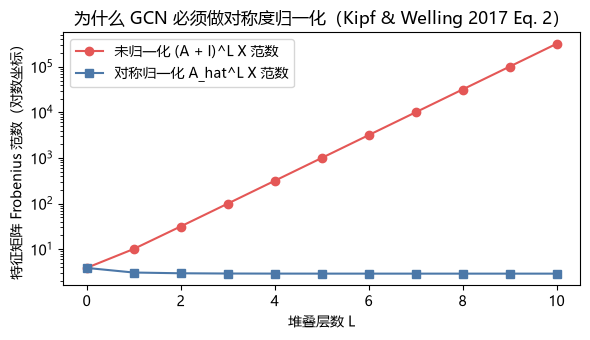

In [4]:
layers = np.arange(0, 11)
norms_raw = [np.linalg.norm(np.linalg.matrix_power(A4_tilde, k) @ X4) for k in layers]
norms_norm = [np.linalg.norm(np.linalg.matrix_power(A4_hat, k) @ X4) for k in layers]

eig_raw = np.linalg.eigvalsh(A4_tilde)
eig_hat = np.linalg.eigvalsh(A4_hat)
print("A_tilde 特征值范围 :", np.round(eig_raw, 4), "最大特征值 =", f"{eig_raw.max():.4f} > 1 (连乘指数爆炸！)")
print("A_hat   特征值范围 :", np.round(eig_hat, 4), "最大特征值 =", f"{eig_hat.max():.4f} = 1 (连乘范数有界！)")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.semilogy(layers, norms_raw, "o-", color="#e45756", label="未归一化 (A + I)^L X 范数")
ax.semilogy(layers, norms_norm, "s-", color="#4c78a8", label="对称归一化 A_hat^L X 范数")
ax.set_xlabel("堆叠层数 L")
ax.set_ylabel("特征矩阵 Frobenius 范数（对数坐标）")
ax.set_title("为什么 GCN 必须做对称度归一化（Kipf & Welling 2017 Eq. 2）")
ax.legend()
plt.tight_layout()
plt.show()
